# Chapter 4. Implementation
## 4.5 Non-Local Means Mapping

The pilot search selects fixed patch settings. The filtering parameter $h$ is then calibrated and the candidate mappings are validated.


## 1. Fixed Patch Setting Selection

Five pilot images are used to select the patch size and search distance.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.denoisers import non_local_means_denoise
from src.metrics import calculate_psnr
from src.noise import add_gaussian_noise
from src.utils import load_grayscale_image


In [2]:
# Experiment settings
noise_levels = [2, 4, 6, 8, 10, 12, 15]
seed = 42
num_calibration = 50
num_validation = 30
num_pilot = 5

# Fixed patch-setting candidates
patch_size_values = [3, 5, 7]
patch_distance_values = [1, 2, 3, 4, 5]

# Coarse h candidates for images normalised to [0, 1]
coarse_h_values = [
    0.005, 0.01, 0.015, 0.02, 0.03, 0.04,
    0.05, 0.06, 0.08, 0.10, 0.12,
    0.15, 0.18, 0.22, 0.26
]

# Fine-search settings around each pilot optimum
fine_half_width = 0.025
fine_step = 0.0025
minimum_h = 0.001
maximum_h = 0.30

calibration_dir = project_dir / "data" / "calibration"
result_dir = project_dir / "results" / "Chapter4_NLM_Calibration"
result_dir.mkdir(parents=True, exist_ok=True)

print("Calibration directory:", calibration_dir)
print("Noise levels (%):", noise_levels)
print("Patch-size candidates:", patch_size_values)
print("Search-distance candidates:", patch_distance_values)
print("Coarse h candidates:", coarse_h_values)
print("Seed:", seed)


Calibration directory: D:\MScProject\data\calibration
Noise levels (%): [2, 4, 6, 8, 10, 12, 15]
Patch-size candidates: [3, 5, 7]
Search-distance candidates: [1, 2, 3, 4, 5]
Coarse h candidates: [0.005, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.1, 0.12, 0.15, 0.18, 0.22, 0.26]
Seed: 42


In [3]:
# Find all image files
image_files = []

for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(calibration_dir.glob(pattern))

image_files = sorted(image_files)
required_images = num_calibration + num_validation

if len(image_files) < required_images:
    raise FileNotFoundError(
        f"At least {required_images} images are required, but only "
        f"{len(image_files)} were found in {calibration_dir}"
    )

# Create reproducible calibration and validation sets
split_rng = np.random.default_rng(seed)
shuffled_indices = split_rng.permutation(len(image_files))
calibration_indices = shuffled_indices[:num_calibration]
validation_indices = shuffled_indices[num_calibration:required_images]

calibration_files = sorted([
    image_files[index]
    for index in calibration_indices
])
validation_files = sorted([
    image_files[index]
    for index in validation_indices
])

# Select five pilot images from the calibration set
pilot_rng = np.random.default_rng(seed)
pilot_indices = pilot_rng.choice(
    len(calibration_files),
    size=num_pilot,
    replace=False
)
pilot_files = [calibration_files[index] for index in pilot_indices]
pilot_names = [image_file.stem for image_file in pilot_files]

# Load the selected clean images
calibration_images = {
    image_file.stem: load_grayscale_image(image_file)
    for image_file in calibration_files
}

validation_images = {
    image_file.stem: load_grayscale_image(image_file)
    for image_file in validation_files
}

print("Number of calibration images:", len(calibration_images))
print("Calibration image IDs:")
print(", ".join(image_file.stem for image_file in calibration_files))

print()
print("Number of validation images:", len(validation_images))
print("Validation image IDs:")
print(", ".join(image_file.stem for image_file in validation_files))

print()
print("Number of pilot images:", len(pilot_files))
print("Pilot image IDs:")
print(", ".join(sorted(pilot_names)))


Number of calibration images: 50
Calibration image IDs:
004, 008, 009, 010, 021, 025, 026, 027, 030, 034, 038, 039, 047, 051, 052, 055, 057, 068, 071, 076, 080, 085, 093, 097, 102, 105, 107, 116, 122, 131, 134, 139, 145, 148, 149, 151, 153, 154, 158, 165, 172, 174, 177, 179, 188, 189, 190, 191, 197, 198

Number of validation images: 30
Validation image IDs:
001, 003, 005, 013, 028, 029, 033, 053, 056, 063, 067, 069, 081, 082, 083, 087, 089, 090, 095, 099, 104, 109, 113, 115, 119, 135, 144, 156, 181, 200

Number of pilot images: 5
Pilot image IDs:
021, 085, 139, 153, 198


In [4]:
# Check the noise scale and parameter values
sample_name, sample_image = next(iter(calibration_images.items()))
sample_noisy = add_gaussian_noise(sample_image, sigma=0.10, seed=seed)

sample_psnr = calculate_psnr(sample_image, sample_noisy)

print(f"Sanity check at 10% noise: {sample_psnr:.2f} dB")

if not 15 <= sample_psnr <= 30:
    raise ValueError(
        "The noise scale appears incorrect. "
        "Check add_gaussian_noise before continuing."
    )

if any(value <= 0 for value in coarse_h_values):
    raise ValueError("Every h candidate must be positive.")

if any(value % 2 == 0 for value in patch_size_values):
    raise ValueError("Patch sizes must be odd positive integers.")


Sanity check at 10% noise: 19.97 dB


In [5]:
# Search fixed patch settings and coarse h values
def evaluate_pilot_candidates(image_name, noise_percent):
    clean_image = calibration_images[image_name]

    # Generate one noisy image for this image-noise case
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)

    image_results = []

    for patch_size in patch_size_values:
        for patch_distance in patch_distance_values:
            for h_value in coarse_h_values:
                denoised_image = non_local_means_denoise(noisy_image, h=h_value, patch_size=patch_size, patch_distance=patch_distance)

                psnr = calculate_psnr(clean_image, denoised_image)

                image_results.append({
                    "image": image_name,
                    "noise_sigma": noise_percent,
                    "patch_size": patch_size,
                    "patch_distance": patch_distance,
                    "h": h_value,
                    "psnr": psnr
                })

    return image_results


pilot_outputs = Parallel(
    n_jobs=16,
    prefer="threads",
    verbose=5
)(
    delayed(evaluate_pilot_candidates)(
        image_name,
        noise_percent
    )
    for noise_percent in noise_levels
    for image_name in pilot_names
)

pilot_results = pd.DataFrame([
    row
    for output in pilot_outputs
    for row in output
])

print("Pilot results:", len(pilot_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  12 out of  35 | elapsed:   14.4s remaining:   27.7s
[Parallel(n_jobs=16)]: Done  20 out of  35 | elapsed:   26.8s remaining:   20.0s
[Parallel(n_jobs=16)]: Done  28 out of  35 | elapsed:   27.4s remaining:    6.8s


Pilot results: 7875


[Parallel(n_jobs=16)]: Done  35 out of  35 | elapsed:   37.3s finished


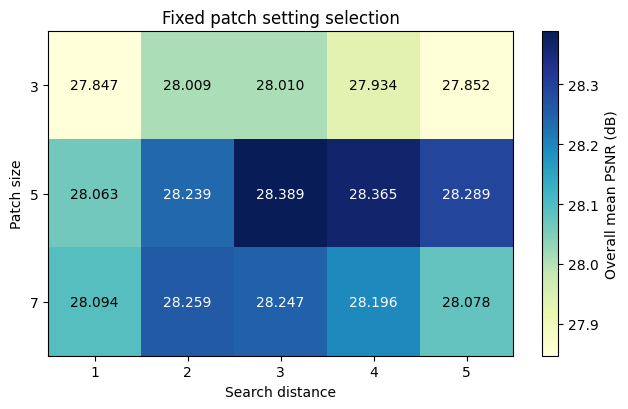

Selected fixed patch size: 5
Selected fixed search distance: 3


,patch_size,patch_distance,overall_mean_psnr
7,5,3,28.388639
8,5,4,28.365106
9,5,5,28.289440
11,7,2,28.259475
12,7,3,28.247372
6,5,2,28.238622
13,7,4,28.195922
10,7,1,28.093902
14,7,5,28.077948
5,5,1,28.062975


,noise_sigma,patch_size,patch_distance,h,psnr
0,2,5,3,0.02,35.490289
1,4,5,3,0.04,31.082886
2,6,5,3,0.06,28.850811
3,8,5,3,0.08,27.378293
4,10,5,3,0.10,26.269377
5,12,5,3,0.12,25.371782
6,15,5,3,0.15,24.277032


,noise_sigma,fine_h_values
0,2,"0.001, 0.0025, 0.005, 0.0075, 0.01, 0.0125, 0...."
1,4,"0.015, 0.0175, 0.02, 0.0225, 0.025, 0.0275, 0...."
2,6,"0.035, 0.0375, 0.04, 0.0425, 0.045, 0.0475, 0...."
3,8,"0.055, 0.0575, 0.06, 0.0625, 0.065, 0.0675, 0...."
4,10,"0.075, 0.0775, 0.08, 0.0825, 0.085, 0.0875, 0...."
5,12,"0.095, 0.0975, 0.1, 0.1025, 0.105, 0.1075, 0.1..."
6,15,"0.125, 0.1275, 0.13, 0.1325, 0.135, 0.1375, 0...."


In [6]:
# Select one patch-size and search-distance combination
pilot_mean = (
    pilot_results
    .groupby(
        ["noise_sigma", "patch_size", "patch_distance", "h"],
        as_index=False
    )["psnr"]
    .mean()
)

# Find the best h for each fixed combination and noise level
pilot_best_indices = (
    pilot_mean
    .groupby(
        ["noise_sigma", "patch_size", "patch_distance"]
    )["psnr"]
    .idxmax()
)
pilot_best_by_setting = (
    pilot_mean.loc[pilot_best_indices]
    .sort_values(
        ["patch_size", "patch_distance", "noise_sigma"]
    )
    .reset_index(drop=True)
)

# Compare each fixed combination using its seven noise-level optima
fixed_setting_summary = (
    pilot_best_by_setting
    .groupby(
        ["patch_size", "patch_distance"],
        as_index=False
    )["psnr"]
    .mean()
    .rename(columns={"psnr": "overall_mean_psnr"})
)

best_setting_index = fixed_setting_summary[
    "overall_mean_psnr"
].idxmax()
patch_size = int(
    fixed_setting_summary.loc[best_setting_index, "patch_size"]
)
patch_distance = int(
    fixed_setting_summary.loc[best_setting_index, "patch_distance"]
)

selected_pilot_best = (
    pilot_best_by_setting[
        (pilot_best_by_setting["patch_size"] == patch_size)
        & (
            pilot_best_by_setting["patch_distance"]
            == patch_distance
        )
    ]
    .sort_values("noise_sigma")
    .reset_index(drop=True)
)

# Build a positive fine h grid around each selected pilot optimum
fine_h_values = {}

for _, row in selected_pilot_best.iterrows():
    noise_percent = int(row["noise_sigma"])
    centre = float(row["h"])
    lower = max(minimum_h, centre - fine_half_width)
    upper = min(maximum_h, centre + fine_half_width)

    first_regular = np.ceil(lower / fine_step) * fine_step
    regular_candidates = np.arange(
        first_regular,
        upper + fine_step / 2,
        fine_step
    )
    candidates = np.concatenate((
        np.array([lower, centre]),
        regular_candidates
    ))
    candidates = np.unique(np.round(candidates, 4))
    candidates = candidates[
        (candidates > 0)
        & (candidates >= minimum_h)
        & (candidates <= maximum_h)
    ]

    if candidates.size == 0:
        raise ValueError(
            f"No valid fine-search h values for {noise_percent}% noise."
        )

    fine_h_values[noise_percent] = candidates.tolist()

    if np.isclose(centre, min(coarse_h_values)) or np.isclose(
        centre,
        max(coarse_h_values)
    ):
        print(
            f"Warning: {noise_percent}% reached a coarse h-search "
            "boundary."
        )

if patch_size in {min(patch_size_values), max(patch_size_values)}:
    print("Warning: the selected patch size is at the search boundary.")

if patch_distance in {
    min(patch_distance_values),
    max(patch_distance_values)
}:
    print("Warning: the selected search distance is at the search boundary.")

fine_range_table = pd.DataFrame({
    "noise_sigma": list(fine_h_values),
    "fine_h_values": [
        ", ".join(map(str, values))
        for values in fine_h_values.values()
    ]
})

# Display the fixed-setting results as a heatmap
fixed_setting_grid = fixed_setting_summary.pivot(
    index="patch_size",
    columns="patch_distance",
    values="overall_mean_psnr"
)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
image = ax.imshow(
    fixed_setting_grid.to_numpy(),
    cmap="YlGnBu",
    aspect="auto"
)

ax.set_xticks(range(len(fixed_setting_grid.columns)))
ax.set_xticklabels(fixed_setting_grid.columns)
ax.set_yticks(range(len(fixed_setting_grid.index)))
ax.set_yticklabels(fixed_setting_grid.index)
ax.set_xlabel("Search distance")
ax.set_ylabel("Patch size")
ax.set_title("Fixed patch setting selection")

for row_index in range(len(fixed_setting_grid.index)):
    for column_index in range(len(fixed_setting_grid.columns)):
        value = fixed_setting_grid.iloc[row_index, column_index]
        ax.text(
            column_index,
            row_index,
            f"{value:.3f}",
            ha="center",
            va="center",
            color=(
                "white"
                if value > fixed_setting_grid.to_numpy().mean()
                else "black"
            )
        )

colour_bar = fig.colorbar(image, ax=ax)
colour_bar.set_label("Overall mean PSNR (dB)")

fig.tight_layout()
fig.savefig(
    result_dir / "nlm_fixed_setting_search.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Selected fixed patch size: {patch_size}")
print(f"Selected fixed search distance: {patch_distance}")
display(fixed_setting_summary.sort_values(
    "overall_mean_psnr",
    ascending=False
))
display(selected_pilot_best)
display(fine_range_table)


## 2. $h$ Calibration

The filtering parameter $h$ is calibrated on all 50 calibration images.


In [7]:
# Run the fine h search on all calibration images
for noise_percent, values in fine_h_values.items():
    if not values or any(h_value <= 0 for h_value in values):
        raise ValueError(
            f"Invalid fine-search h values for {noise_percent}%: {values}"
        )


def evaluate_calibration_image(image_name, clean_image, noise_percent):
    # Generate one noisy image for this image-noise case
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)

    image_results = []

    for h_value in fine_h_values[noise_percent]:
        denoised_image = non_local_means_denoise(noisy_image, h=h_value, patch_size=patch_size, patch_distance=patch_distance)

        psnr = calculate_psnr(
            clean_image,
            denoised_image,
        )

        image_results.append({
            "image": image_name,
            "noise_sigma": noise_percent,
            "seed": seed,
            "patch_size": patch_size,
            "patch_distance": patch_distance,
            "h": h_value,
            "psnr": psnr
        })

    return image_results


fine_outputs = Parallel(
    n_jobs=16,
    prefer="threads",
    verbose=5
)(
    delayed(evaluate_calibration_image)(
        image_name,
        clean_image,
        noise_percent
    )
    for noise_percent in noise_levels
    for image_name, clean_image in calibration_images.items()
)

grid_results = pd.DataFrame([
    row
    for output in fine_outputs
    for row in output
])

print("Fine-search results:", len(grid_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    3.0s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    9.6s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:   20.3s


Fine-search results: 7250


[Parallel(n_jobs=16)]: Done 350 out of 350 | elapsed:   27.8s finished


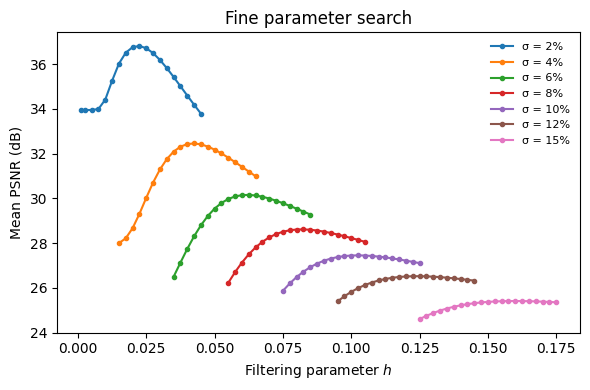

,noise_sigma,h,psnr
0,2,0.0225,36.804801
1,4,0.0425,32.452630
2,6,0.0625,30.154085
3,8,0.0825,28.613848
4,10,0.1025,27.453769
5,12,0.1250,26.522809
6,15,0.1600,25.413971


In [8]:
# Average PSNR across the fifty calibration images
mean_results = (
    grid_results
    .groupby(["noise_sigma", "h"], as_index=False)["psnr"]
    .mean()
)

# Select the h value with the highest mean PSNR
best_indices = mean_results.groupby("noise_sigma")["psnr"].idxmax()
best_parameters = (
    mean_results.loc[best_indices]
    .sort_values("noise_sigma")
    .reset_index(drop=True)
)

# Check whether an optimum reached a fine-search boundary
for _, row in best_parameters.iterrows():
    noise_percent = int(row["noise_sigma"])
    selected_h = float(row["h"])
    current_range = fine_h_values[noise_percent]

    if np.isclose(selected_h, min(current_range)) or np.isclose(
        selected_h,
        max(current_range)
    ):
        print(
            f"Warning: {noise_percent}% reached a fine h-search "
            "boundary."
        )

# Plot the fine-search curves
fig, ax = plt.subplots(figsize=(6, 4))

for noise_percent in noise_levels:
    current = mean_results[
        mean_results["noise_sigma"] == noise_percent
    ]

    ax.plot(
        current["h"],
        current["psnr"],
        marker="o",
        markersize=3,
        label=f"σ = {noise_percent}%"
    )

ax.set_xlabel(r"Filtering parameter $h$")
ax.set_ylabel("Mean PSNR (dB)")
ax.set_title("Fine parameter search")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(
    result_dir / "nlm_fine_search.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

best_parameters


Fixed patch size: 5
Fixed search distance: 3
Mapping: h = 0.010489σ -0.000054
R² = 0.9987


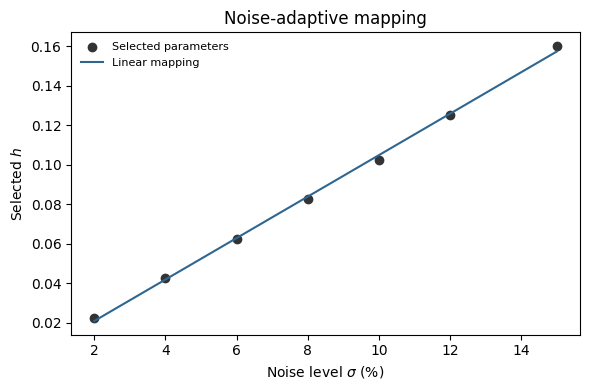

,noise_sigma,h,psnr
0,2,0.0225,36.804801
1,4,0.0425,32.452630
2,6,0.0625,30.154085
3,8,0.0825,28.613848
4,10,0.1025,27.453769
5,12,0.1250,26.522809
6,15,0.1600,25.413971


,patch_size,patch_distance,slope,intercept,r_squared,minimum_h,maximum_h
0,5,3,0.010489,-0.000054,0.998667,0.0225,0.16


In [9]:
# Fit a linear noise-to-h mapping
noise_values = best_parameters["noise_sigma"].to_numpy(dtype=float)
h_values = best_parameters["h"].to_numpy(dtype=float)

slope, intercept = np.polyfit(noise_values, h_values, 1)
fitted_values = slope * noise_values + intercept

residual_sum = np.sum((h_values - fitted_values) ** 2)
total_sum = np.sum((h_values - np.mean(h_values)) ** 2)
r_squared = 1 - residual_sum / total_sum if total_sum > 0 else 0.0

# Keep fitted values inside the calibrated h range
minimum_selected_h = float(h_values.min())
maximum_selected_h = float(h_values.max())

mapping = pd.DataFrame({
    "patch_size": [patch_size],
    "patch_distance": [patch_distance],
    "slope": [slope],
    "intercept": [intercept],
    "r_squared": [r_squared],
    "minimum_h": [minimum_selected_h],
    "maximum_h": [maximum_selected_h]
})

print(f"Fixed patch size: {patch_size}")
print(f"Fixed search distance: {patch_distance}")
print(f"Mapping: h = {slope:.6f}σ {intercept:+.6f}")
print(f"R² = {r_squared:.4f}")

if r_squared < 0.98:
    print(
        "Note: the linear fit is relatively weak. "
        "Inspect the calibration points before finalising the model."
    )

# Plot the selected parameters and fitted mapping
fig, ax = plt.subplots(figsize=(6, 4))
plot_noise = np.linspace(min(noise_values), max(noise_values), 200)

ax.scatter(
    noise_values,
    h_values,
    color="#333333",
    label="Selected parameters"
)
ax.plot(
    plot_noise,
    slope * plot_noise + intercept,
    color="#2F6690",
    label="Linear mapping"
)

ax.set_xlabel(r"Noise level $\sigma$ (%)")
ax.set_ylabel(r"Selected $h$")
ax.set_title("Noise-adaptive mapping")
ax.legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(
    result_dir / "nlm_parameter_mapping.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(best_parameters)
display(mapping)


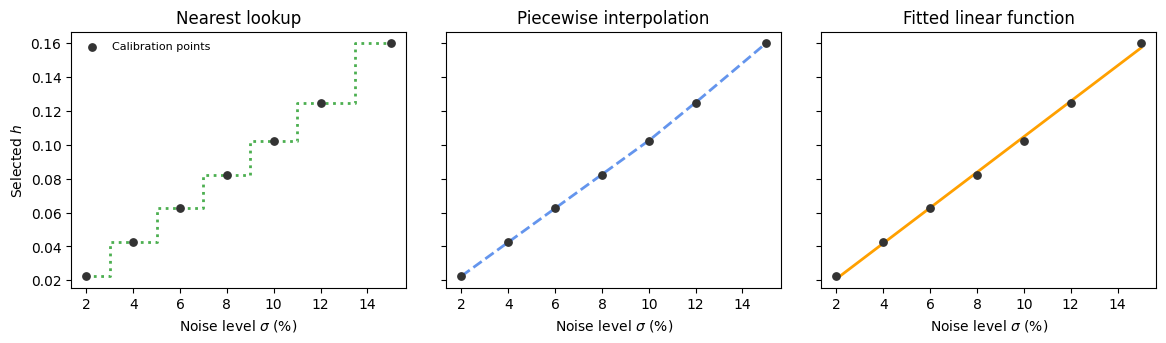

,noise_sigma,lookup_h,interpolated_h,fitted_h
0,2,0.0225,0.022500,0.022500
1,3,0.0225,0.032500,0.031413
2,4,0.0425,0.042500,0.041902
3,5,0.0425,0.052500,0.052391
4,6,0.0625,0.062500,0.062880
5,7,0.0625,0.072500,0.073370
6,8,0.0825,0.082500,0.083859
7,9,0.0825,0.092500,0.094348
8,10,0.1025,0.102500,0.104837
9,11,0.1025,0.113750,0.115326


In [10]:
# Define the three candidate mapping strategies
def select_h_lookup(estimated_sigma_percent):
    distances = np.abs(noise_values - estimated_sigma_percent)
    nearest_index = int(np.argmin(distances))
    return float(h_values[nearest_index])


def select_h_interpolated(estimated_sigma_percent):
    return float(np.interp(estimated_sigma_percent, noise_values, h_values))


def select_h_fitted(estimated_sigma_percent):
    h_value = slope * estimated_sigma_percent + intercept
    return float(np.clip(h_value, minimum_selected_h, maximum_selected_h))


# Add noise levels between the calibration points
intermediate_noise_levels = [3, 5, 7, 9, 11, 13, 14]
validation_noise_levels = sorted(set(noise_levels + intermediate_noise_levels))

# Display the parameters returned by all three strategies
mapping_comparison = pd.DataFrame({
    "noise_sigma": validation_noise_levels,
    "lookup_h": [
        select_h_lookup(value)
        for value in validation_noise_levels
    ],
    "interpolated_h": [
        select_h_interpolated(value)
        for value in validation_noise_levels
    ],
    "fitted_h": [
        select_h_fitted(value)
        for value in validation_noise_levels
    ]
})

# Plot lookup, interpolation, and the fitted function
plot_noise = np.linspace(min(noise_values), max(noise_values), 400)
lookup_plot = [select_h_lookup(value) for value in plot_noise]
interpolated_plot = [
    select_h_interpolated(value)
    for value in plot_noise
]
fitted_plot = [select_h_fitted(value) for value in plot_noise]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)

# Nearest lookup
axes[0].scatter(
    noise_values,
    h_values,
    color="#333333",
    s=28,
    label="Calibration points",
    zorder=4
)
axes[0].step(
    plot_noise,
    lookup_plot,
    where="mid",
    color="#4CAF50",
    linewidth=2,
    linestyle=":"
)
axes[0].set_title("Nearest lookup")

# Piecewise interpolation
axes[1].scatter(
    noise_values,
    h_values,
    color="#333333",
    s=28,
    zorder=4
)
axes[1].plot(
    plot_noise,
    interpolated_plot,
    color="#6495ED",
    linewidth=2,
    linestyle="--"
)
axes[1].set_title("Piecewise interpolation")

# Fitted linear function
axes[2].scatter(
    noise_values,
    h_values,
    color="#333333",
    s=28,
    zorder=4
)
axes[2].plot(
    plot_noise,
    fitted_plot,
    color="#FFA000",
    linewidth=2
)
axes[2].set_title("Fitted linear function")

for ax in axes:
    ax.set_xlabel(r"Noise level $\sigma$ (%)")

axes[0].set_ylabel(r"Selected $h$")
axes[0].legend(frameon=False, fontsize=8)

fig.subplots_adjust(top=0.82, bottom=0.18, wspace=0.12)
fig.savefig(
    result_dir / "nlm_mapping_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

mapping_comparison


## 3. Validation

The three mappings are compared on 30 validation images. The intermediate noise levels are used for final selection.


In [11]:
# Evaluate the three mapping strategies on the validation images
def validate_image(image_name, clean_image, noise_percent):
    # Generate one noisy image and reuse it for all three strategies
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)

    lookup_h = select_h_lookup(noise_percent)
    interpolated_h = select_h_interpolated(noise_percent)
    fitted_h = select_h_fitted(noise_percent)

    lookup_image = non_local_means_denoise(noisy_image, h=lookup_h, patch_size=patch_size, patch_distance=patch_distance)
    interpolated_image = non_local_means_denoise(noisy_image, h=interpolated_h, patch_size=patch_size, patch_distance=patch_distance)
    fitted_image = non_local_means_denoise(noisy_image, h=fitted_h, patch_size=patch_size, patch_distance=patch_distance)

    return {
        "image": image_name,
        "noise_sigma": noise_percent,
        "patch_size": patch_size,
        "patch_distance": patch_distance,
        "lookup_h": lookup_h,
        "interpolated_h": interpolated_h,
        "fitted_h": fitted_h,
        "noisy_psnr": calculate_psnr(clean_image, noisy_image),
        "lookup_psnr": calculate_psnr(clean_image, lookup_image),
        "interpolated_psnr": calculate_psnr(clean_image, interpolated_image),
        "fitted_psnr": calculate_psnr(clean_image, fitted_image)
    }


validation_rows = Parallel(
    n_jobs=16,
    prefer="threads",
    verbose=5
)(
    delayed(validate_image)(
        image_name,
        clean_image,
        noise_percent
    )
    for noise_percent in validation_noise_levels
    for image_name, clean_image in validation_images.items()
)

validation_results = pd.DataFrame(validation_rows)
validation_summary = (
    validation_results
    .groupby("noise_sigma", as_index=False)[
        [
            "lookup_h",
            "interpolated_h",
            "fitted_h",
            "noisy_psnr",
            "lookup_psnr",
            "interpolated_psnr",
            "fitted_psnr"
        ]
    ]
    .mean()
)

# Select the final strategy using only the intermediate noise levels
intermediate_results = validation_results[
    validation_results["noise_sigma"].isin(intermediate_noise_levels)
]
mean_noisy_psnr = intermediate_results["noisy_psnr"].mean()

method_rows = []

for method_name, psnr_column in [
    ("Nearest lookup", "lookup_psnr"),
    ("Piecewise interpolation", "interpolated_psnr"),
    ("Fitted linear function", "fitted_psnr")
]:
    mean_psnr = intermediate_results[psnr_column].mean()
    method_rows.append({
        "mapping_method": method_name,
        "mean_psnr": mean_psnr,
        "gain_over_noisy": mean_psnr - mean_noisy_psnr
    })

validation_method_summary = (
    pd.DataFrame(method_rows)
    .sort_values("mean_psnr", ascending=False)
    .reset_index(drop=True)
)

selected_mapping_method = validation_method_summary.loc[
    0,
    "mapping_method"
]

print("Selected mapping method:", selected_mapping_method)
display(validation_summary)
display(validation_method_summary)


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:    0.6s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:    1.8s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:    3.5s


Selected mapping method: Piecewise interpolation


[Parallel(n_jobs=16)]: Done 420 out of 420 | elapsed:    5.7s finished


,noise_sigma,lookup_h,interpolated_h,fitted_h,noisy_psnr,lookup_psnr,interpolated_psnr,fitted_psnr
0,2,0.0225,0.022500,0.022500,33.945304,37.201979,37.201979,37.201979
1,3,0.0225,0.032500,0.031413,30.423479,33.463243,34.622865,34.606904
2,4,0.0425,0.042500,0.041902,27.924704,32.882321,32.882321,32.877815
3,5,0.0425,0.052500,0.052391,25.986504,31.012979,31.582928,31.582539
4,6,0.0625,0.062500,0.062880,24.402879,30.555099,30.555099,30.555918
5,7,0.0625,0.072500,0.073370,23.063943,29.378565,29.709145,29.710735
6,8,0.0825,0.082500,0.083859,21.904104,28.990651,28.990651,28.993064
7,9,0.0825,0.092500,0.094348,20.881053,28.136434,28.364915,28.368480
8,10,0.1025,0.102500,0.104837,19.965904,27.808297,27.808297,27.813146
9,11,0.1025,0.113750,0.115326,19.138050,27.129093,27.309851,27.311561


,mapping_method,mean_psnr,gain_over_noisy
0,Piecewise interpolation,29.151682,7.119766
1,Fitted linear function,29.150196,7.118281
2,Nearest lookup,28.776479,6.744563


In [12]:
# Show validation results at intermediate noise levels
intermediate_summary = validation_summary[
    validation_summary["noise_sigma"].isin(intermediate_noise_levels)
].copy()

validation_table = (
    intermediate_summary[
        [
            "noise_sigma",
            "lookup_psnr",
            "interpolated_psnr",
            "fitted_psnr"
        ]
    ]
    .rename(columns={
        "noise_sigma": "Noise level (%)",
        "lookup_psnr": "Nearest lookup",
        "interpolated_psnr": "Piecewise interpolation",
        "fitted_psnr": "Fitted linear function"
    })
)

mean_row = pd.DataFrame({
    "Noise level (%)": ["Mean"],
    "Nearest lookup": [intermediate_results["lookup_psnr"].mean()],
    "Piecewise interpolation": [
        intermediate_results["interpolated_psnr"].mean()
    ],
    "Fitted linear function": [
        intermediate_results["fitted_psnr"].mean()
    ]
})

validation_table = pd.concat(
    [validation_table, mean_row],
    ignore_index=True
).round(4)

print("Mean PSNR (dB):")
display(validation_table)


Mean PSNR (dB):


,Noise level (%),Nearest lookup,Piecewise interpolation,Fitted linear function
0,3,33.4632,34.6229,34.6069
1,5,31.0130,31.5829,31.5825
2,7,29.3786,29.7091,29.7107
3,9,28.1364,28.3649,28.3685
4,11,27.1291,27.3099,27.3116
5,13,26.3278,26.4311,26.4310
6,14,25.9872,26.0410,26.0402
7,Mean,28.7765,29.1517,29.1502
